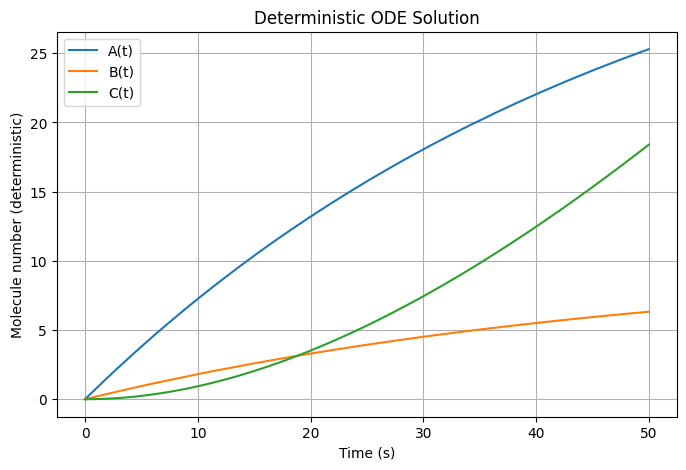

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameters
k1v = 1.0
k2 = 50.0
k3 = 200.0
k4 = 0.1

# ODE system
def reaction_system(t, y):
    A, B, C = y

    dA = k1v - k2*A + k3*B
    dB = k2*A - k3*B - k4*B
    dC = k4*B

    return [dA, dB, dC]

# Initial conditions
y0 = [0.0, 0.0, 0.0]

# Time span
t_span = (0, 50)
t_eval = np.linspace(0, 50, 1000)

# Solve ODEs
sol = solve_ivp(
    reaction_system,
    t_span,
    y0,
    t_eval=t_eval,
    method='RK45'
)

# Extract solution
A = sol.y[0]
B = sol.y[1]
C = sol.y[2]

# Plot
plt.figure(figsize=(8,5))
plt.plot(sol.t, A, label='A(t)')
plt.plot(sol.t, B, label='B(t)')
plt.plot(sol.t, C, label='C(t)')
plt.xlabel('Time (s)')
plt.ylabel('Molecule number (deterministic)')
plt.title('Deterministic ODE Solution')
plt.legend()
plt.grid(True)
plt.show()

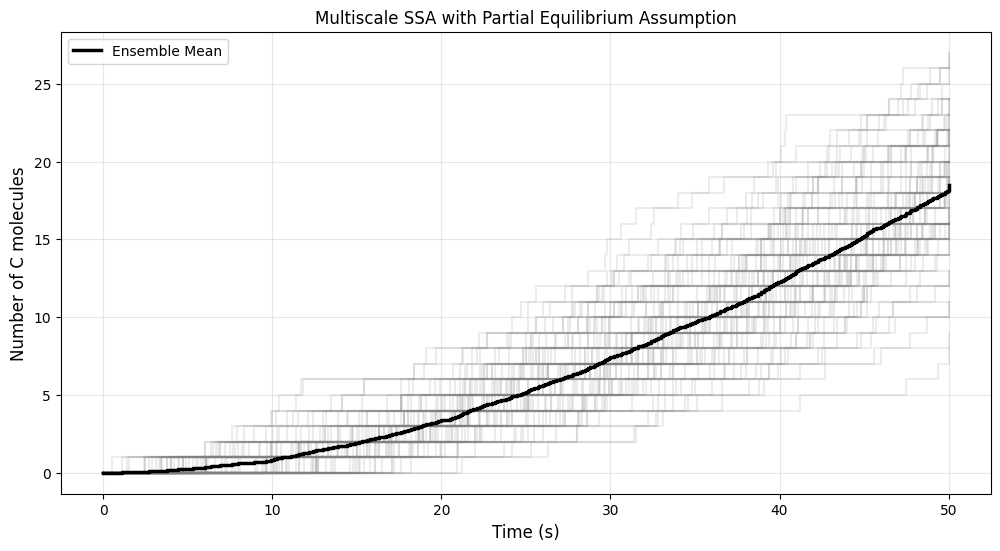

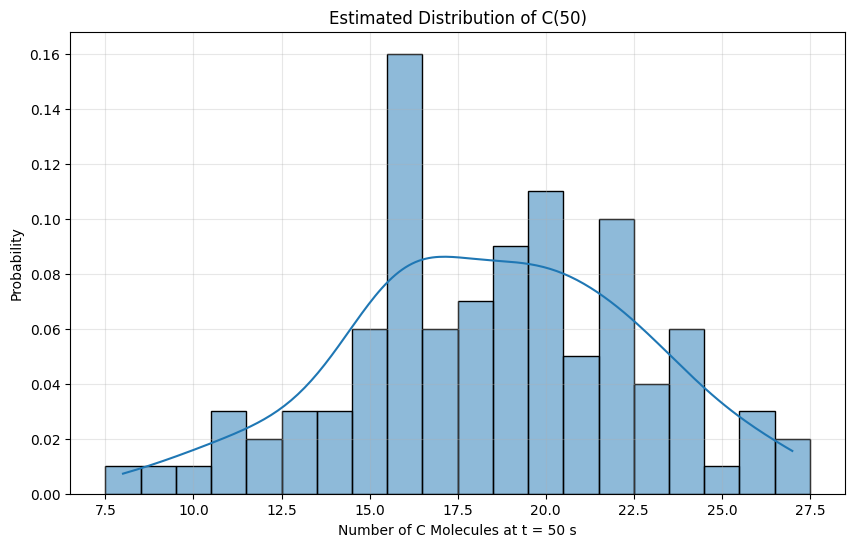

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math
import random
from numba import njit
import seaborn as sns

# ============================================================
# Multiscale SSA for the reaction network
#
#       ∅  ->  A
#       A <-> B
#       B  ->  C
#
# The reactions A <-> B are much faster than the other two
# reactions, so we assume they are always at equilibrium.
#
# Instead of simulating A and B directly, we keep track of
#
#       Q = A + B
#
# and use the equilibrium distribution of the fast subsystem
# to estimate how much B is present on average.
#
# This allows us to skip ~99.9% of reaction events while
# still obtaining a good approximation for C(t).
# ============================================================


# ------------------------------------------------------------
# Rate constants from the textbook example
# ------------------------------------------------------------

k1v = 1.0      # ∅ -> A
k2  = 50.0     # A -> B
k3  = 200.0    # B -> A
k4  = 0.1      # B -> C


# ------------------------------------------------------------
# Simulation settings
# ------------------------------------------------------------

mt = 50.0      # total simulation time
dt = 0.1       # spacing of output samples


@njit
def multiscale_ssa(k1v, k2, k3, k4, mt, dt, conc, idx):

    # --------------------------------------------------------
    # Initial state
    #
    # Q = total number of molecules participating in the
    # fast subsystem (A + B)
    #
    # C is our slow species of interest.
    # --------------------------------------------------------

    Q = 0
    C = 0

    # Current simulation time
    t = 0.0

    # Time on the regular output grid
    t_grid = 0.0

    # Position in the output array
    j = 0

    # Store initial condition
    conc[idx, 0] = C

    while True:

        # Stop once we reach the requested final time
        if t >= mt:
            break

        # ====================================================
        # Compute effective propensities
        # ====================================================

        # The source reaction happens at a constant rate,
        # so its propensity never changes.
        abar1 = k1v

        # We assume the fast subsystem A <-> B has already
        # reached equilibrium.
        #
        # At equilibrium:
        #
        #     k2*A = k3*B
        #
        # which leads to
        #
        #     E[B|Q] = Q*k2/(k2+k3)
        #
        # Instead of tracking B explicitly, we use its
        # expected equilibrium value.
        mean_B = Q * k2 / (k2 + k3)

        # The slow reaction B -> C depends on B.
        # Since we are no longer simulating B directly,
        # we use the equilibrium average amount of B.
        abar4 = k4 * mean_B

        # Total effective propensity
        abar0 = abar1 + abar4

        # Safety check
        if abar0 <= 0.0:
            break

        # ====================================================
        # Gillespie Step 1:
        # Sample the waiting time until the next slow reaction
        # ====================================================

        r1 = random.random()

        tau = (1.0 / abar0) * math.log(1.0 / r1)

        t += tau

        # ====================================================
        # Record the trajectory on a uniform time grid.
        #
        # Gillespie produces events at irregular times, but
        # plotting and averaging is much easier if every run
        # is sampled on the same set of time points.
        # ====================================================

        while (t_grid + dt) <= t and (t_grid + dt) <= mt:

            j += 1
            t_grid += dt

            if j >= conc.shape[1]:
                break

            conc[idx, j] = C

        # ====================================================
        # Gillespie Step 2:
        # Decide which slow reaction occurred
        # ====================================================

        r2 = random.random()

        # ----------------------------------------------------
        # Reaction 1:
        #
        #       ∅ -> A
        #
        # This adds one molecule to the fast subsystem.
        # Since Q = A + B, Q increases by one.
        # ----------------------------------------------------

        if r2 < (abar1 / abar0):

            Q += 1

        # ----------------------------------------------------
        # Reaction 2:
        #
        #       B -> C
        #
        # One molecule leaves the fast subsystem and becomes C.
        #
        # Q decreases by one because there is one fewer
        # molecule in the A/B pool.
        # ----------------------------------------------------

        else:

            Q -= 1
            C += 1

            # Numerical safeguard
            if Q < 0:
                Q = 0

    # ========================================================
    # Fill any remaining output locations with the final value
    # so every trajectory has the same length.
    # ========================================================

    while j < conc.shape[1] - 1:

        j += 1
        conc[idx, j] = C


# ============================================================
# Create a uniform observation grid
# ============================================================

time_grid = np.arange(0, mt + dt, dt)


# ============================================================
# Run many independent realizations
# ============================================================

n_paths = 100

conc = np.zeros((n_paths, len(time_grid)))

for i in range(n_paths):

    multiscale_ssa(
        k1v,
        k2,
        k3,
        k4,
        mt,
        dt,
        conc,
        i
    )


# ============================================================
# Visualize the ensemble
# ============================================================

plt.figure(figsize=(12, 6))

# Plot every trajectory as a faint grey line so we can see
# the variability between realizations.
for i in range(n_paths):

    plt.step(
        time_grid,
        conc[i],
        where='post',
        color='gray',
        alpha=0.15
    )

# Plot the ensemble mean on top.
plt.step(
    time_grid,
    np.mean(conc, axis=0),
    where='post',
    color='black',
    linewidth=2.5,
    label='Ensemble Mean'
)

plt.xlabel('Time (s)', fontsize=12)
plt.ylabel('Number of C molecules', fontsize=12)
plt.title('Multiscale SSA with Partial Equilibrium Assumption')
plt.legend()
plt.grid(alpha=0.3)

plt.figure(figsize=(10, 6))

final_C = conc[:, -1]

sns.histplot(
    final_C,
    stat='probability',
    discrete=True,
    kde=True,
    edgecolor='black'
)

plt.xlabel('Number of C Molecules at t = 50 s')
plt.ylabel('Probability')
plt.title('Estimated Distribution of C(50)')

plt.grid(alpha=0.3)
plt.show()



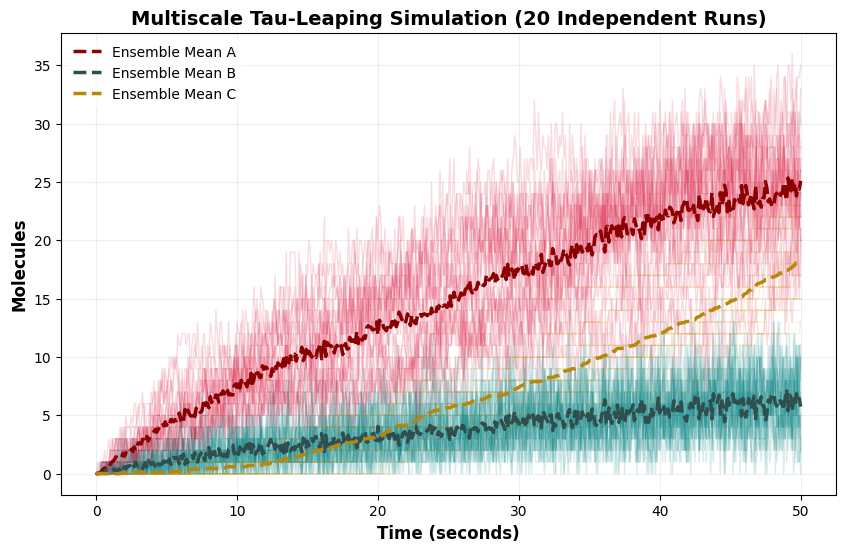

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Simulation Parameters
mt = 50                  # Maximum time (seconds)
dt = 0.1                 # Plotting sampling interval
tau_leap = 0.001         # Leap interval
num_simulations = 20     # Increased to 20 runs

# Rate Constants
k1v = 1.0
k2 = 50.0
k3 = 200.0
k4 = 0.1

meantime = np.arange(0, mt + 0.001, dt)

# 3D arrays to store historical data for species A, B, and C
conc_A = np.zeros((num_simulations, len(meantime)))
conc_B = np.zeros((num_simulations, len(meantime)))
conc_C = np.zeros((num_simulations, len(meantime)))

def multiscale_tau_leaping(i):
    # Initial conditions (assuming starting with 0 molecules)
    A = 0
    B = 0
    C = 0
    t = 0
    j = 0
    
    # Store initial state
    conc_A[i, 0] = A
    conc_B[i, 0] = B
    conc_C[i, 0] = C
    
    while t < mt:
        # 1. Calculate Propensities for all 4 reactions
        a1 = k1v
        a2 = k2 * A
        a3 = k3 * B
        a4 = k4 * B
        
        # 2. Sample number of firings for each channel independently using Poisson
        num_R1 = np.random.poisson(a1 * tau_leap)
        num_R2 = np.random.poisson(a2 * tau_leap)
        num_R3 = np.random.poisson(a3 * tau_leap)
        num_R4 = np.random.poisson(a4 * tau_leap)
        
        # 3. Handle physical boundaries (cannot consume more than available)
        if num_R2 > A:
            num_R2 = A
            
        total_B_consumed = num_R3 + num_R4
        if total_B_consumed > B and B > 0:
            fraction_R3 = num_R3 / total_B_consumed
            num_R3 = int(np.round(fraction_R3 * B))
            num_R4 = B - num_R3
        elif B == 0:
            num_R3 = 0
            num_R4 = 0

        # 4. Update the populations based on stoichiometry
        A = A + num_R1 - num_R2 + num_R3
        B = B + num_R2 - num_R3 - num_R4
        C = C + num_R4
        
        t += tau_leap
        
        # 5. Log data to tracking grid
        while j < len(meantime) and meantime[j] <= t:
            conc_A[i, j] = A
            conc_B[i, j] = B
            conc_C[i, j] = C
            j += 1

# Run all 20 simulations
for i in range(num_simulations):
    multiscale_tau_leaping(i)

# Plotting Results
plt.figure(figsize=(10, 6))

# Loop through and plot all 20 individual stochastic trajectories without labels
for i in range(num_simulations):
    plt.plot(meantime, conc_A[i], color='crimson', alpha=0.15, lw=1)
    plt.plot(meantime, conc_B[i], color='teal', alpha=0.15, lw=1)
    plt.plot(meantime, conc_C[i], color='goldenrod', alpha=0.15, lw=1)

# Plot Ensemble Mean across all 20 runs (Thick dashed lines)
plt.plot(meantime, np.mean(conc_A, axis=0), color='darkred', linestyle='--', lw=2.5, label='Ensemble Mean A')
plt.plot(meantime, np.mean(conc_B, axis=0), color='darkslategrey', linestyle='--', lw=2.5, label='Ensemble Mean B')
plt.plot(meantime, np.mean(conc_C, axis=0), color='darkgoldenrod', linestyle='--', lw=2.5, label='Ensemble Mean C')

plt.xlabel('Time (seconds)', fontsize=12, fontweight='bold')
plt.ylabel('Molecules', fontsize=12, fontweight='bold')
plt.title('Multiscale Tau-Leaping Simulation (20 Independent Runs)', fontsize=14, fontweight='bold')
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
plt.grid(True, alpha=0.2)
plt.show()